# Acne: do the new photos and the reviewed labels help? (training inside the notebook)

**Question.** After you boxed 250 new acne photos and reviewed 111 training photos, does adding them improve the acne detector?
**Method.** The same recipe and the same seed (42) as the baseline, one change at a time, always scored on the same 154 validation photos. The development test and independent sets are not used here.

| variant | training data |
|---|---|
| baseline A0 (already trained) | acne dataset v4, 1,145 photos |
| **C1** | v4 + 250 new photos you boxed |
| **C2** | C1 + the 111 training photos you reviewed (missed spots added) |
| **C3** | C2 + 115 healthy-skin negatives (no boxes) |

**Decision rule (fixed before looking):** a variant is adopted only if validation mAP@0.5 rises by at least 0.02 over the baseline and neither precision nor recall falls by more than 0.02. Photo-level AUC is checked afterwards for the winner.

**How to read the output.** Each finished epoch prints one line: epoch, the three training losses, and precision / recall / mAP on the validation photos. `*` marks a new best mAP@0.5.

In [1]:
import os, sys, json, time, shutil
os.environ["YOLO_VERBOSE"] = "False"          # no progress bars: one clean line per epoch is printed below
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, "/mnt/c/Users/Bautista/source/repos/SkinDevApp/ml")
import lesion_exp as LE
from ultralytics import YOLO
import torch, yaml
VARIANTS = ["C1_acne_new", "C2_acne_new_review", "C3_acne_new_review_neg"]
RUN_VARIANTS = VARIANTS                   # remove names here to train fewer variants
print("runs are saved in", LE.RUNS)

runs are saved in /home/bautista/PrecisionSkinV1/lesion_experiments/runs


## 1. The data of each variant

In [2]:
for v in VARIANTS:
    sp = next(s for s in LE.QUEUE if s["id"] == v); train, vals, note = LE.recipe(sp["recipe"])
    nb = sum(len([l for l in (Path(str(p).replace("/images/", "/labels/")).with_suffix(".txt")).read_text().splitlines() if l.strip()]) if Path(str(p).replace("/images/", "/labels/")).with_suffix(".txt").exists() else 0 for p in train)
    print("%-26s %5d training images | %6d boxes | %s" % (v, len(train), nb, note))
print("validation photos:", len(list((LE.ACNE / "val" / "images").glob("*"))), "(same for every variant)")

C1_acne_new                 1395 training images |  14528 boxes | acne v4 train + new photos (250 new, 0 reviewed)


acne_c2: 250 new photos, 111 reviewed labels replaced


C2_acne_new_review          1395 training images |  15082 boxes | acne v4 train + new photos (250 new, 111 reviewed)


acne_c3: 250 new photos, 111 reviewed labels replaced


C3_acne_new_review_neg      1510 training images |  15082 boxes | acne v4 train + new photos (250 new, 111 reviewed)
validation photos: 154 (same for every variant)


## 2. Training (one variant after the other)
Same settings as every earlier acne run: YOLOv8s, 800 px, up to 100 epochs, early stopping after 30 epochs without improvement, seed 42.

In [3]:
def train_variant(vid):
    sp = next(s for s in LE.QUEUE if s["id"] == vid); train, vals, note = LE.recipe(sp["recipe"]); args = dict(sp["args"]); model = args.pop("model")
    run = LE.RUNS / vid; run.mkdir(parents=True, exist_ok=True)
    lst = run / "train_list.txt"; lst.write_text("\n".join(str(p) for p in train) + "\n"); first_val = next(iter(vals.values()))
    yml = run / "data.yaml"; yaml.safe_dump({"path": str(run), "train": str(lst), "val": str(first_val / "images"), "names": {0: sp["condition"]}}, open(yml, "w"))
    (run / "spec.json").write_text(json.dumps(sp, indent=1)); best = {"v": 0.0}
    def on_epoch(trainer):
        m = trainer.metrics; ls = trainer.label_loss_items(trainer.tloss, prefix="train"); mp = m.get("metrics/mAP50(B)", 0.0); star = "*" if mp > best["v"] else " "
        best["v"] = max(best["v"], mp)
        print("%s epoch %3d/%d | box %.3f cls %.3f dfl %.3f | P %.3f R %.3f mAP50 %.3f mAP50-95 %.3f" % (star, trainer.epoch + 1, trainer.epochs, ls["train/box_loss"], ls["train/cls_loss"], ls["train/dfl_loss"],
              m.get("metrics/precision(B)", 0), m.get("metrics/recall(B)", 0), mp, m.get("metrics/mAP50-95(B)", 0)), flush=True)
    t0 = time.time(); last = run / "weights" / "last.pt"; print("=" * 110); print(vid, "|", note, "| %d training images" % len(train), flush=True)
    if (run / "weights" / "best.pt").exists() and (run / "DONE").exists(): print("already trained: using the saved run"); return
    mdl = YOLO(str(last)) if last.exists() else YOLO(model)
    mdl.add_callback("on_fit_epoch_end", on_epoch)
    if last.exists(): mdl.train(resume=True)
    else: mdl.train(data=str(yml), seed=sp["seed"], device=0 if torch.cuda.is_available() else "cpu", project=str(LE.RUNS), name=vid, exist_ok=True, plots=False, **args)
    (run / "DONE").write_text("ok"); print("trained in %.1f minutes" % ((time.time() - t0) / 60), flush=True)

for v in RUN_VARIANTS: train_variant(v)

C1_acne_new | acne v4 train + new photos (250 new, 0 reviewed) | 1395 training images


* epoch   1/100 | box 1.909 cls 2.530 dfl 1.414 | P 0.333 R 0.334 mAP50 0.247 mAP50-95 0.072


* epoch   2/100 | box 1.711 cls 1.668 dfl 1.314 | P 0.386 R 0.364 mAP50 0.303 mAP50-95 0.087


  epoch   3/100 | box 1.722 cls 1.636 dfl 1.316 | P 0.363 R 0.376 mAP50 0.274 mAP50-95 0.078


* epoch   4/100 | box 1.654 cls 1.579 dfl 1.297 | P 0.394 R 0.375 mAP50 0.306 mAP50-95 0.092


...

  epoch  55/100 | box 1.353 cls 0.985 dfl 1.153 | P 0.484 R 0.495 mAP50 0.404 mAP50-95 0.126


  epoch  56/100 | box 1.357 cls 0.985 dfl 1.159 | P 0.495 R 0.490 mAP50 0.415 mAP50-95 0.131


  epoch  57/100 | box 1.323 cls 0.958 dfl 1.149 | P 0.461 R 0.517 mAP50 0.412 mAP50-95 0.130


  epoch  58/100 | box 1.323 cls 0.958 dfl 1.149 | P 0.487 R 0.469 mAP50 0.423 mAP50-95 0.137


trained in 25.9 minutes


## 3. Training curves
Validation mAP should rise and flatten; the best epoch is kept.

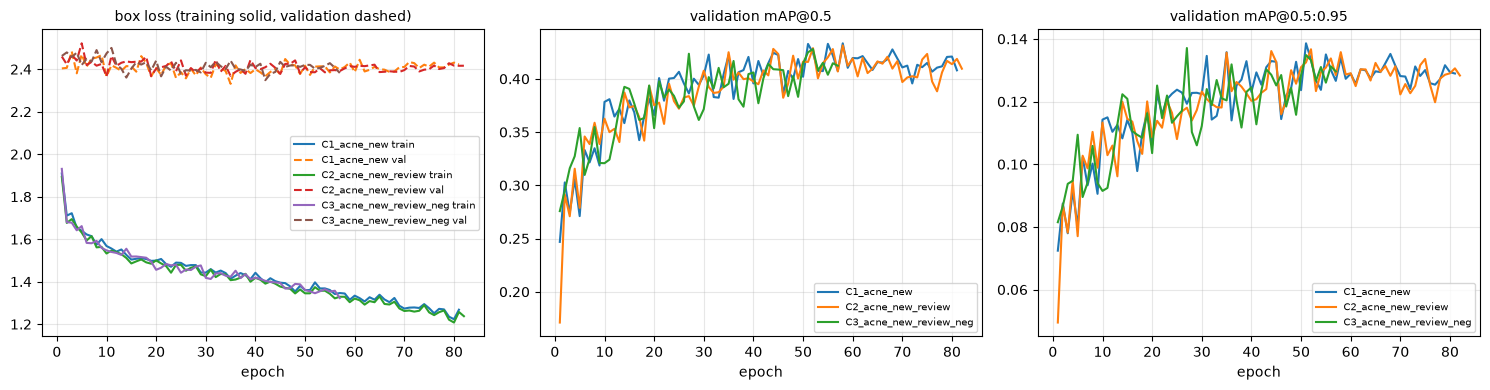

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for v in VARIANTS:
    f = LE.RUNS / v / "results.csv"
    if not f.exists(): continue
    r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]
    ax[0].plot(r["epoch"], r["train/box_loss"], label=v + " train"); ax[0].plot(r["epoch"], r["val/box_loss"], "--", label=v + " val"); ax[1].plot(r["epoch"], r["metrics/mAP50(B)"], label=v); ax[2].plot(r["epoch"], r["metrics/mAP50-95(B)"], label=v)
for a, t in zip(ax, ("box loss (training solid, validation dashed)", "validation mAP@0.5", "validation mAP@0.5:0.95")): a.set_title(t, fontsize=10); a.set_xlabel("epoch"); a.legend(fontsize=7); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Every finished epoch of every variant
Saved per-epoch records (a `*` marks a new best mAP@0.5). Scroll the tables; they stay in this notebook.

In [5]:
pd.set_option("display.max_rows", None); pd.set_option("display.width", 220)
cols = {"epoch": "epoch", "train/box_loss": "box_loss", "train/cls_loss": "cls_loss", "train/dfl_loss": "dfl_loss", "metrics/precision(B)": "P", "metrics/recall(B)": "R", "metrics/mAP50(B)": "mAP50", "metrics/mAP50-95(B)": "mAP50-95", "val/box_loss": "val_box_loss"}
for v in VARIANTS:
    f = LE.RUNS / v / "results.csv"
    if not f.exists(): print(v, ": no results yet"); continue
    r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]; t = r[list(cols)].rename(columns=cols); t["epoch"] = t["epoch"].astype(int); t["best so far"] = np.where(t["mAP50"] == t["mAP50"].cummax(), "*", "")
    print("=" * 100); print("%s | %d finished epochs | best mAP@0.5 %.3f at epoch %d" % (v, len(t), t["mAP50"].max(), int(t.loc[t["mAP50"].idxmax(), "epoch"]))); display(t.round(3).set_index("epoch"))

C1_acne_new | 81 finished epochs | best mAP@0.5 0.433 at epoch 58


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,val_box_loss,best so far
epoch,,,,,,,,,
1,1.909,2.530,1.414,0.333,0.334,0.247,0.072,2.404,*
2,1.711,1.668,1.314,0.386,0.364,0.303,0.087,2.406,*
3,1.722,1.636,1.316,0.363,0.376,0.274,0.078,2.483,
4,1.654,1.579,1.297,0.394,0.375,0.306,0.092,2.381,*
5,1.639,1.582,1.285,0.354,0.350,0.271,0.080,2.469,
6,1.622,1.511,1.276,0.413,0.403,0.333,0.102,2.412,*
7,1.614,1.489,1.268,0.406,0.359,0.322,0.093,2.449,
8,1.574,1.422,1.249,0.444,0.398,0.335,0.100,2.455,*
9,1.600,1.459,1.263,0.383,0.394,0.319,0.091,2.466,


C2_acne_new_review | 82 finished epochs | best mAP@0.5 0.431 at epoch 58


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,val_box_loss,best so far
epoch,,,,,,,,,
1,1.893,2.480,1.402,0.233,0.343,0.171,0.049,2.460,*
2,1.677,1.636,1.294,0.359,0.394,0.291,0.087,2.423,*
3,1.694,1.597,1.303,0.353,0.348,0.271,0.078,2.469,
4,1.660,1.570,1.288,0.395,0.383,0.316,0.095,2.441,*
5,1.631,1.542,1.280,0.367,0.383,0.279,0.077,2.522,
6,1.594,1.448,1.277,0.403,0.411,0.346,0.103,2.419,*
7,1.614,1.427,1.271,0.423,0.403,0.339,0.099,2.435,
8,1.561,1.397,1.244,0.443,0.415,0.359,0.110,2.417,*
9,1.564,1.412,1.261,0.424,0.409,0.339,0.099,2.425,


C3_acne_new_review_neg | 57 finished epochs | best mAP@0.5 0.428 at epoch 52


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,val_box_loss,best so far
epoch,,,,,,,,,
1,1.931,2.610,1.424,0.352,0.356,0.276,0.082,2.462,*
2,1.680,1.639,1.299,0.364,0.376,0.295,0.087,2.479,*
3,1.678,1.556,1.305,0.380,0.383,0.316,0.094,2.457,*
4,1.642,1.503,1.302,0.431,0.359,0.327,0.095,2.478,*
5,1.661,1.496,1.294,0.443,0.405,0.354,0.109,2.420,*
6,1.582,1.434,1.266,0.389,0.397,0.310,0.090,2.449,
7,1.581,1.446,1.258,0.406,0.407,0.325,0.094,2.436,
8,1.592,1.449,1.262,0.444,0.382,0.355,0.106,2.490,*
9,1.559,1.448,1.247,0.427,0.356,0.321,0.094,2.433,


## 5. Comparison on the same validation photos
Every model (best epoch) scored with the same scorer; the confidence is the one with the best F1 on the validation photos. Baseline = the earlier A0 run of the same recipe on the v4 data.

In [6]:
import hyperpig_autolabel as H
rows = []
base = pd.read_csv(LE.REG) if hasattr(LE, "REG") else pd.read_csv(Path.home() / "PrecisionSkinV1/lesion_experiments/EXPERIMENTS.csv")
b = base[(base.id == "A0_base")].iloc[0]; rows.append(dict(run="A0 baseline (v4)", mAP50=b.val_mAP50, mAP50_95=b.val_mAP50_95, precision=b.val_P, recall=b.val_R, F1=b.val_F1, dmAP50=0.0, adopt=""))
for v in VARIANTS:
    w = LE.RUNS / v / "weights" / "best.pt"
    if not w.exists(): continue
    sv = H.score_model(w, 800, LE.ACNE / "val"); c = H.best_f1_conf(sv); p, r, f = H.at_conf(sv, c); d = sv["AP50"] - b.val_mAP50
    ok = d >= 0.02 and p >= b.val_P - 0.02 and r >= b.val_R - 0.02
    rows.append(dict(run=v, mAP50=sv["AP50"], mAP50_95=sv["AP50_95"], precision=p, recall=r, F1=f, dmAP50=d, adopt="YES (passes the rule)" if ok else "no"))
CMP = pd.DataFrame(rows); display(CMP.round(3))
CMP.to_csv(Path.home() / "PrecisionSkinV1/lesion_experiments/acne_data_comparison.csv", index=False)
print("rule: adopt only if mAP@0.5 gains at least +0.02 and neither precision nor recall drops by more than 0.02 (single seed: seed noise is about +/-0.006)")

,run,mAP50,mAP50_95,precision,recall,F1,dmAP50,adopt
0,A0 baseline (v4),0.425,0.136,0.486,0.503,0.494,0.000,
1,C1_acne_new,0.439,0.139,0.497,0.496,0.497,0.014,no
2,C2_acne_new_review,0.429,0.135,0.478,0.513,0.495,0.004,no
3,C3_acne_new_review_neg,0.435,0.136,0.493,0.475,0.484,0.009,no


rule: adopt only if mAP@0.5 gains at least +0.02 and neither precision nor recall drops by more than 0.02 (single seed: seed noise is about +/-0.006)


## 6. Summary
Read the table above: the `dmAP50` column is the gain over the baseline on the same 154 validation photos; `adopt` applies the pre-set rule. If a variant passes, the next step is to train it with three seeds (also in a notebook), choose the threshold on validation, and score the development test and the independent set once.